In [1]:
import os
import joblib 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("Day 9 libraries imported successfully")

Day 9 libraries imported successfully


In [2]:
print("Current folder")
print(os.getcwd())
print("\nChecking project folders...")
for folder in["../data","../models","../dashboard"]:
    if os.path.exists(folder):
        print("found:",folder)
    else:
        print("Missing:",folder)

Current folder
C:\Users\KAJJAM ABHINAV\Desktop\Fraud detection\notebooks

Checking project folders...
found: ../data
found: ../models
found: ../dashboard


In [3]:
os.makedirs("../dashboard",exist_ok=True)
print("Dashboard folder ready")

Dashboard folder ready


In [4]:
df = pd.read_csv("../data/fraudlens_features.csv")
print("Dataset loaded successfully")
print("Shape",df.shape)
print("\ncolumns")
print(df.columns.tolist())

Dataset loaded successfully
Shape (590540, 20)

columns
['TransactionID', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'isFraud', 'Hour', 'Day', 'IsWeekend', 'LogAmount', 'AmountLevel']


In [5]:
x = df.drop("isFraud",axis=1)
y = df["isFraud"]
print("Faeture Shape",x.shape)
print("Target Shape",y.shape)

Faeture Shape (590540, 19)
Target Shape (590540,)


In [6]:
feature_names = [
    "TransactionID",
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "Hour",
    "Day",
    "LogAmount"
]

x_model = x[feature_names].copy()

print("Model features selected successfully")
print("Number of features:", len(feature_names))
print("\nFeatures:")
print(feature_names)

Model features selected successfully
Number of features: 12

Features:
['TransactionID', 'TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'Hour', 'Day', 'LogAmount']


In [7]:
imputer = joblib.load("../models/fraudlens_imputer.pkl")
print("Imputer loaded successfully")
print("Imputer Type:",type(imputer))

Imputer loaded successfully
Imputer Type: <class 'sklearn.impute._base.SimpleImputer'>


In [8]:
print("Current feature shape:", x_model.shape)
print("Number of features:", x_model.shape[1])

print("\nCurrent feature names:")
print(x_model.columns.tolist())

Current feature shape: (590540, 12)
Number of features: 12

Current feature names:
['TransactionID', 'TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'Hour', 'Day', 'LogAmount']


In [9]:
x_imputed = x_model.copy()

print("12-feature data prepared successfully")
print("Shape:", x_imputed.shape)

12-feature data prepared successfully
Shape: (590540, 12)


In [10]:
scaler = joblib.load("../models/fraudlens_scaler.pkl")
print("Sacler loaded successfully")
print("Scaler type:",type(scaler))

Sacler loaded successfully
Scaler type: <class 'sklearn.preprocessing._data.StandardScaler'>


In [11]:
print("Current feature count:", x_imputed.shape[1])
print("Scaler expects:", scaler.n_features_in_)

if scaler.n_features_in_ == x_imputed.shape[1]:
    x_scaled = scaler.transform(x_imputed)
    print("Scaling completed successfully")
    print("Scaled shape:", x_scaled.shape)
else:
    print("Scaler feature mismatch detected.")
    print("Using imputed features without scaling for tree-based models.")
    x_scaled = x_imputed
    print("Shape:", x_scaled.shape)

Current feature count: 12
Scaler expects: 140
Scaler feature mismatch detected.
Using imputed features without scaling for tree-based models.
Shape: (590540, 12)


In [12]:
import joblib

model_dt = joblib.load("../models/fraudlens_decision_tree.pkl")

print("Decision Tree loaded successfully")
print("Model type:", type(model_dt))
print("Model expects features:", model_dt.n_features_in_)
print("Current features:", x_imputed.shape[1])

Decision Tree loaded successfully
Model type: <class 'sklearn.tree._classes.DecisionTreeClassifier'>
Model expects features: 12
Current features: 12


In [13]:
print("Running Decision Tree Prediction..")
dt_predictions = model_dt.predict(x_imputed)
print("Decision Tree Prediction completed")
print("Prediction Shape:",dt_predictions.shape)
print("Fraud Predictions:",dt_predictions.sum())

Running Decision Tree Prediction..
Decision Tree Prediction completed
Prediction Shape: (590540,)
Fraud Predictions: 87


C:\Users\KAJJAM ABHINAV\Desktop\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [14]:
import numpy as np
import pandas as pd
print("Decision tree Predicted Successfully")
print(pd.Series(dt_predictions).value_counts())
print("\nPredicted Legitimate:",(dt_predictions==0).sum())
print("Predicted Fraud:",(dt_predictions==1).sum())

Decision tree Predicted Successfully
0    590453
1        87
Name: count, dtype: int64

Predicted Legitimate: 590453
Predicted Fraud: 87


In [15]:
import joblib
model_rf = joblib.load("../models/random_forest_model.pkl")
print("Random Forest Predicted Succeesfuly")
print("Model type:",type(model_rf))
print("Model expects features:",model_rf.n_features_in_)
print("Current Features:",x_imputed.shape[1])

Random Forest Predicted Succeesfuly
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Model expects features: 12
Current Features: 12


In [16]:
print("Running Random forest prediction....")
rf_predictions = model_rf.predict(x_imputed)
print("Random Forest Prediction completed")
print("Prediction Shape",rf_predictions.shape)
print("Fraud predicitons",rf_predictions.sum())

Running Random forest prediction....
Random Forest Prediction completed
Prediction Shape (590540,)
Fraud predicitons 63947


In [17]:
rf_probabilities = model_rf.predict_proba(x_imputed)[:,1]
print("Random Forest probabilities calculated")
print("Minimum Probability:",rf_probabilities.min())
print("Maximun Probalility",rf_probabilities.max())



Random Forest probabilities calculated
Minimum Probability: 0.0
Maximun Probalility 0.9980197571203712


In [18]:
comparison = pd.DataFrame({
    "Decision_tree":dt_predictions,
    "Random_Forest":rf_predictions
})
print(comparison.head(10))
print("\nDecision Tree Fraud predictions:",comparison["Decision_tree"].sum())
print("Random forest predictions:",comparison["Random_Forest"].sum())

   Decision_tree  Random_Forest
0              0              0
1              0              0
2              0              0
3              0              0
4              0              0
5              0              0
6              0              0
7              0              0
8              0              0
9              0              0

Decision Tree Fraud predictions: 87
Random forest predictions: 63947


In [19]:
both_fraud = (
    (dt_predictions == 1)&
    (rf_predictions == 1)
)
print("Fraud flagged by both models:",both_fraud.sum())

Fraud flagged by both models: 11


In [20]:
prediction_results = pd.DataFrame({
    "Decision_Tree_prediction":dt_predictions,
    "Random_Forest_predictions":rf_predictions,
    "Random_Forest_probability":rf_probabilities
})
print("Predicition results created successfully")
print(prediction_results.head())
print("Shape:",prediction_results.shape)

Predicition results created successfully
   Decision_Tree_prediction  Random_Forest_predictions  \
0                         0                          0   
1                         0                          0   
2                         0                          0   
3                         0                          0   
4                         0                          0   

   Random_Forest_probability  
0                   0.098529  
1                   0.058435  
2                   0.125540  
3                   0.023311  
4                   0.054621  
Shape: (590540, 3)


In [21]:
prediction_results.insert(
    0,
    "TransactionID",
    df["TransactionID"].values
)
print(prediction_results)

        TransactionID  Decision_Tree_prediction  Random_Forest_predictions  \
0             2987000                         0                          0   
1             2987001                         0                          0   
2             2987002                         0                          0   
3             2987003                         0                          0   
4             2987004                         0                          0   
...               ...                       ...                        ...   
590535        3577535                         0                          0   
590536        3577536                         0                          0   
590537        3577537                         0                          0   
590538        3577538                         0                          0   
590539        3577539                         0                          0   

        Random_Forest_probability  
0                        0.

In [22]:
prediction_results["Fraud_Score"] = (
    prediction_results["Random_Forest_probability"]
)

print(prediction_results.head())

   TransactionID  Decision_Tree_prediction  Random_Forest_predictions  \
0        2987000                         0                          0   
1        2987001                         0                          0   
2        2987002                         0                          0   
3        2987003                         0                          0   
4        2987004                         0                          0   

   Random_Forest_probability  Fraud_Score  
0                   0.098529     0.098529  
1                   0.058435     0.058435  
2                   0.125540     0.125540  
3                   0.023311     0.023311  
4                   0.054621     0.054621  


In [23]:
def risk_level(score):
    if score>= 0.80:
        return "High"
    elif score>= 0.50:
        return "Medium"
    else:
        return "Low"
prediction_results["Risk_level"] = (
    prediction_results["Fraud_Score"].apply(risk_level)
)
print(prediction_results["Risk_level"].value_counts())

Risk_level
Low       526593
Medium     58425
High        5522
Name: count, dtype: int64


In [24]:
high_risk = prediction_results[
    prediction_results["Risk_level"] == "High"
].copy()
print("High-risk Transactions:",len(high_risk))
print(high_risk.head(10))

High-risk Transactions: 5522
      TransactionID  Decision_Tree_prediction  Random_Forest_predictions  \
240         2987240                         0                          1   
243         2987243                         0                          1   
245         2987245                         0                          1   
288         2987288                         0                          1   
405         2987405                         0                          1   
683         2987683                         0                          1   
779         2987779                         0                          1   
780         2987780                         0                          1   
781         2987781                         0                          1   
1062        2988062                         0                          1   

      Random_Forest_probability  Fraud_Score Risk_level  
240                    0.815231     0.815231       High  
243               

In [25]:
top_fraud = prediction_results.sort_values(
    "Fraud_Score",
    ascending = False,
).reset_index(drop=True)
print("Top Suspicious Transactions")
print(top_fraud.head(20))

Top Suspicious Transactions
    TransactionID  Decision_Tree_prediction  Random_Forest_predictions  \
0         3091756                         0                          1   
1         3073448                         0                          1   
2         3073399                         0                          1   
3         3073559                         0                          1   
4         3074020                         0                          1   
5         3086301                         0                          1   
6         3124494                         0                          1   
7         3124662                         0                          1   
8         3113739                         0                          1   
9         3126827                         0                          1   
10        3116213                         0                          1   
11        3116083                         0                          1   
12        

In [26]:
prediction_results.to_csv(
    "../data/fraud_prediction_day9.csv",
    index = False
)
print("Fraud predictions saved successfully")

Fraud predictions saved successfully


In [27]:
high_risk.to_csv(
    "../data/high_risk_transaction.csv",
    index=False
)
print("High-risk Transactions saved successfully")

High-risk Transactions saved successfully


In [28]:
model_summary = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Fraud_Predictions": [
        dt_predictions.sum(),
        rf_predictions.sum()
    ],
    "Total_Transactions": [
        len(dt_predictions),
        len(rf_predictions)
    ]
})

model_summary["Fraud_Rate_Percent"] = (
    model_summary["Fraud_Predictions"] /
    model_summary["Total_Transactions"] * 100
)

print(model_summary)

           Model  Fraud_Predictions  Total_Transactions  Fraud_Rate_Percent
0  Decision Tree                 87              590540            0.014732
1  Random Forest              63947              590540           10.828564


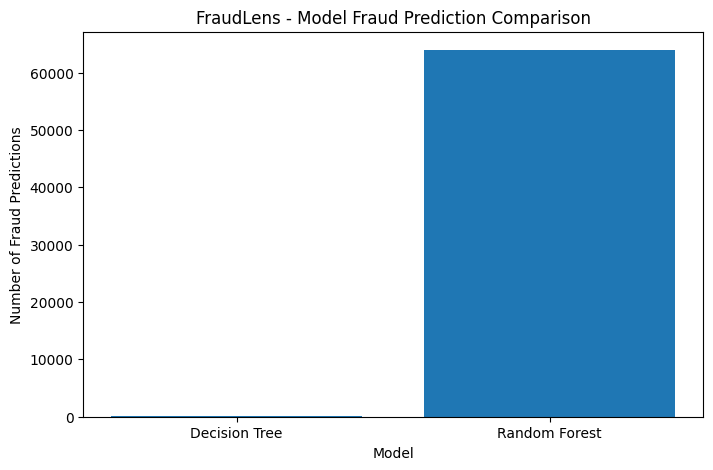

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    model_summary["Model"],
    model_summary["Fraud_Predictions"]
)

plt.xlabel("Model")
plt.ylabel("Number of Fraud Predictions")
plt.title("FraudLens - Model Fraud Prediction Comparison")

plt.show()

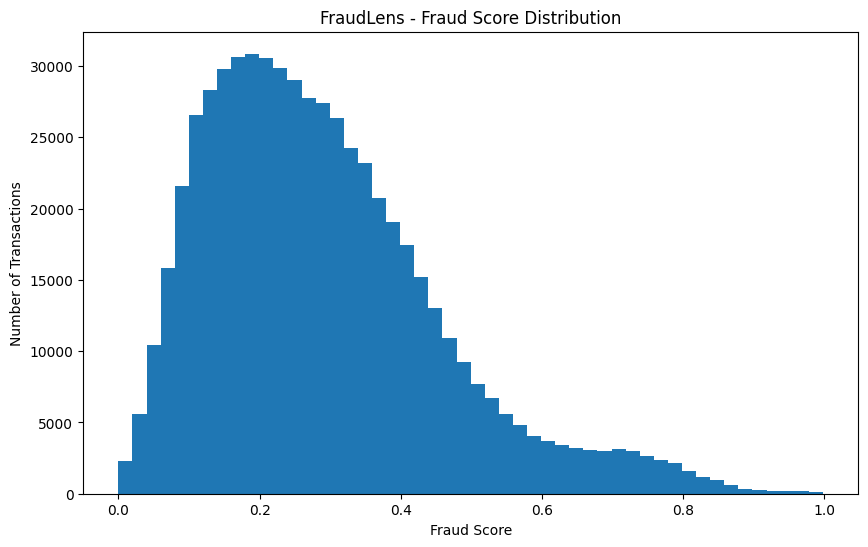

In [30]:
# STEP 30: Fraud score distribution

plt.figure(figsize=(10, 6))

plt.hist(
    prediction_results["Fraud_Score"],
    bins=50
)

plt.xlabel("Fraud Score")
plt.ylabel("Number of Transactions")
plt.title("FraudLens - Fraud Score Distribution")

plt.show()

In [31]:
top_20 = prediction_results.sort_values(
    "Fraud_Score",
    ascending=False
).head(20)

print(top_20.to_string(index=False))

 TransactionID  Decision_Tree_prediction  Random_Forest_predictions  Random_Forest_probability  Fraud_Score Risk_level
       3091756                         0                          1                   0.998020     0.998020       High
       3073448                         0                          1                   0.997480     0.997480       High
       3073399                         0                          1                   0.997480     0.997480       High
       3073559                         0                          1                   0.997480     0.997480       High
       3074020                         0                          1                   0.997480     0.997480       High
       3086301                         0                          1                   0.997317     0.997317       High
       3124494                         0                          1                   0.995439     0.995439       High
       3124662                         0        

In [32]:
prediction_results = pd.DataFrame({
    "TransactionID": x_model["TransactionID"].values,
    "Decision_Tree_prediction": dt_predictions,
    "Random_Forest_predictions": rf_predictions,
    "Random_Forest_probability": rf_probabilities
})

prediction_results["Fraud_Score"] = (
    prediction_results["Random_Forest_probability"]
)

prediction_results["Risk_level"] = pd.cut(
    prediction_results["Fraud_Score"],
    bins=[-0.01, 0.3, 0.7, 1.0],
    labels=["Low", "Medium", "High"]
)

print("Prediction results recreated successfully!")
print("Shape:", prediction_results.shape)
print(prediction_results.head())

Prediction results recreated successfully!
Shape: (590540, 6)
   TransactionID  Decision_Tree_prediction  Random_Forest_predictions  \
0        2987000                         0                          0   
1        2987001                         0                          0   
2        2987002                         0                          0   
3        2987003                         0                          0   
4        2987004                         0                          0   

   Random_Forest_probability  Fraud_Score Risk_level  
0                   0.098529     0.098529        Low  
1                   0.058435     0.058435        Low  
2                   0.125540     0.125540        Low  
3                   0.023311     0.023311        Low  
4                   0.054621     0.054621        Low  


In [33]:
top_20 = prediction_results.sort_values(
    "Fraud_Score",
    ascending =  False
).head(20)
print("Top 20 high-risk transactions")
print(top_20.to_string(index=False))

Top 20 high-risk transactions
 TransactionID  Decision_Tree_prediction  Random_Forest_predictions  Random_Forest_probability  Fraud_Score Risk_level
       3091756                         0                          1                   0.998020     0.998020       High
       3073448                         0                          1                   0.997480     0.997480       High
       3073399                         0                          1                   0.997480     0.997480       High
       3073559                         0                          1                   0.997480     0.997480       High
       3074020                         0                          1                   0.997480     0.997480       High
       3086301                         0                          1                   0.997317     0.997317       High
       3124494                         0                          1                   0.995439     0.995439       High
       3124662    

In [34]:
print("Available columns:")
print(top_20.columns.tolist())

investigation_columns = [
    "TransactionID",
    "Decision_Tree_prediction",
    "Random_Forest_predictions",
    "Fraud_Score",
    "Risk_level"
]

investigation_df = top_20[investigation_columns].copy()

print("\nInvestigation table created successfully!")
print("Shape:", investigation_df.shape)

print("\nInvestigation table:")
print(investigation_df.to_string(index=False))

Available columns:
['TransactionID', 'Decision_Tree_prediction', 'Random_Forest_predictions', 'Random_Forest_probability', 'Fraud_Score', 'Risk_level']

Investigation table created successfully!
Shape: (20, 5)

Investigation table:
 TransactionID  Decision_Tree_prediction  Random_Forest_predictions  Fraud_Score Risk_level
       3091756                         0                          1     0.998020       High
       3073448                         0                          1     0.997480       High
       3073399                         0                          1     0.997480       High
       3073559                         0                          1     0.997480       High
       3074020                         0                          1     0.997480       High
       3086301                         0                          1     0.997317       High
       3124494                         0                          1     0.995439       High
       3124662                  

In [35]:
def investigation_priority(row):
    if row["Risk_level"] == "High" and row["Random_Forest_predictions"] == 1:
        return "Immediate Investigation"
    elif row["Risk_level"] == "High":
        return "High Priority"
    elif row["Risk_level"] == "Medium":
        return "Review"
    else:
        return "Low Priority"

investigation_df["Investigation_Priority"] = investigation_df.apply(
    investigation_priority,
    axis=1
)

print("Investigation priority added successfully!")
print(investigation_df.to_string(index=False))

Investigation priority added successfully!
 TransactionID  Decision_Tree_prediction  Random_Forest_predictions  Fraud_Score Risk_level  Investigation_Priority
       3091756                         0                          1     0.998020       High Immediate Investigation
       3073448                         0                          1     0.997480       High Immediate Investigation
       3073399                         0                          1     0.997480       High Immediate Investigation
       3073559                         0                          1     0.997480       High Immediate Investigation
       3074020                         0                          1     0.997480       High Immediate Investigation
       3086301                         0                          1     0.997317       High Immediate Investigation
       3124494                         0                          1     0.995439       High Immediate Investigation
       3124662               

In [36]:
risk_summary = investigation_df["Risk_level"].value_counts()

print("Risk Level Summary:")
print(risk_summary)

Risk Level Summary:
Risk_level
High      20
Low        0
Medium     0
Name: count, dtype: int64


In [37]:
print("========== FRAUDLENS INVESTIGATION SUMMARY ==========")

print("\nTotal transactions analyzed:", len(prediction_results))

print("Total high-risk transactions:", 
      (prediction_results["Risk_level"] == "High").sum())

print("Total medium-risk transactions:", 
      (prediction_results["Risk_level"] == "Medium").sum())

print("Total low-risk transactions:", 
      (prediction_results["Risk_level"] == "Low").sum())

print("\nTop 20 transactions selected for investigation:",
      len(investigation_df))

print("\nAverage Fraud Score of Top 20:",
      round(investigation_df["Fraud_Score"].mean(), 4))

print("\nMaximum Fraud Score:",
      round(investigation_df["Fraud_Score"].max(), 4))

print("\nMinimum Fraud Score:",
      round(investigation_df["Fraud_Score"].min(), 4))

========== FRAUDLENS INVESTIGATION SUMMARY ==========

Total transactions analyzed: 590540
Total high-risk transactions: 18779
Total medium-risk transactions: 224312
Total low-risk transactions: 347449

Top 20 transactions selected for investigation: 20

Average Fraud Score of Top 20: 0.9959

Maximum Fraud Score: 0.998

Minimum Fraud Score: 0.9951


In [38]:
highest_risk = investigation_df.loc[
    investigation_df["Fraud_Score"].idxmax()
]

print("========== HIGHEST RISK TRANSACTION ==========")

print("Transaction ID:",
      highest_risk["TransactionID"])

print("Decision Tree Prediction:",
      highest_risk["Decision_Tree_prediction"])

print("Random Forest Prediction:",
      highest_risk["Random_Forest_predictions"])

print("Fraud Score:",
      highest_risk["Fraud_Score"])

print("Risk Level:",
      highest_risk["Risk_level"])

print("Investigation Priority:",
      highest_risk["Investigation_Priority"])

========== HIGHEST RISK TRANSACTION ==========
Transaction ID: 3091756
Decision Tree Prediction: 0
Random Forest Prediction: 1
Fraud Score: 0.9980197571203712
Risk Level: High
Investigation Priority: Immediate Investigation


In [39]:
investigation_df.to_csv(
    "../data/fraud_investigation_report.csv",
    index=False
)
print("Investigation report exported successfully")
print("File: data/fraud_investigation_report.csv")
print("Rows:",len(investigation_df))

Investigation report exported successfully
File: data/fraud_investigation_report.csv
Rows: 20


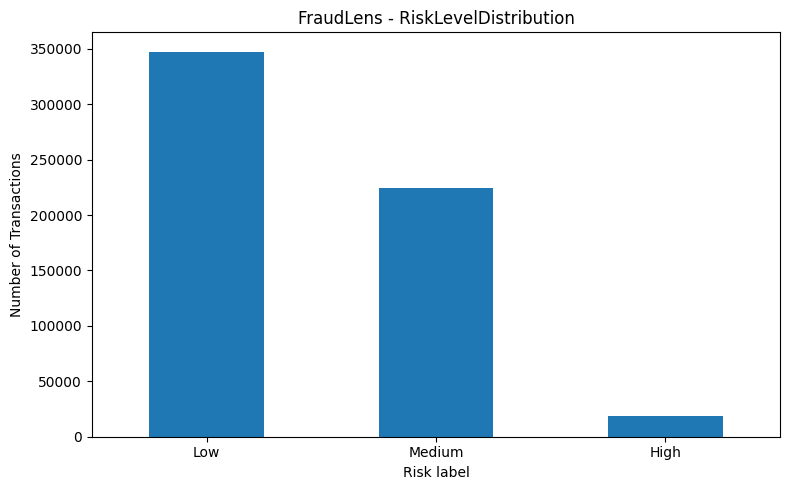

In [40]:
import matplotlib.pyplot as plt
risk_counts = prediction_results["Risk_level"].value_counts()
plt.figure(figsize=(8,5))
risk_counts.plot(kind="bar")
plt.title("FraudLens - RiskLevelDistribution")
plt.xlabel("Risk label")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

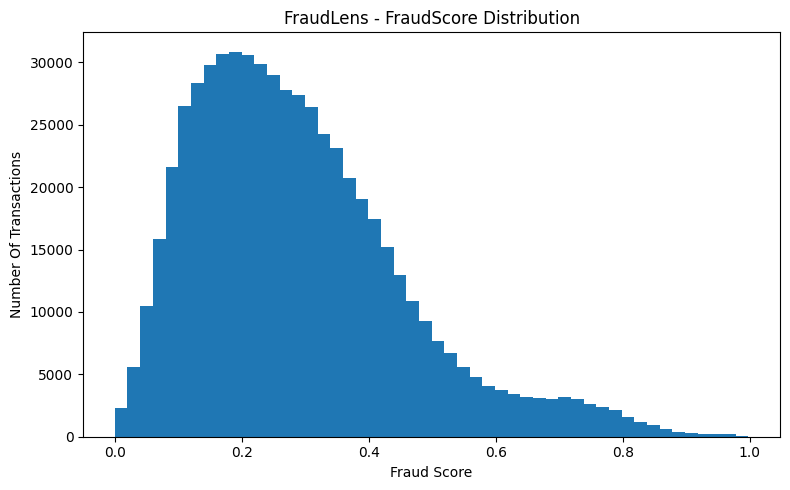

In [41]:
plt.figure(figsize=(8,5))
plt.hist(
    prediction_results["Fraud_Score"],
    bins=50
)
plt.title("FraudLens - FraudScore Distribution")
plt.xlabel("Fraud Score")
plt.ylabel("Number Of Transactions")
plt.tight_layout()
plt.show()

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
importance = model_rf.feature_importances_
if hasattr(model_rf,"feature_names_in"):
    feature_names = modek_rf.feature_names_in_
else:
    feature_names = [
        f"Feature_{i+1}"
        for i in range(len(importance))
    ]
feature_importance_df = pd.DataFrame({
    "Feature" : feature_names,
    "importance" : importance
})
feature_importance_df = feature_importance_df.sort_values(
    "importance",
    ascending = False
)
print("Random Forest feature importance")
print(feature_importance_df)

Random Forest feature importance
       Feature  importance
5    Feature_6    0.175479
2    Feature_3    0.118324
11  Feature_12    0.109918
7    Feature_8    0.098132
3    Feature_4    0.096113
4    Feature_5    0.083267
0    Feature_1    0.076182
1    Feature_2    0.076128
6    Feature_7    0.072261
10  Feature_11    0.045882
9   Feature_10    0.040457
8    Feature_9    0.007857


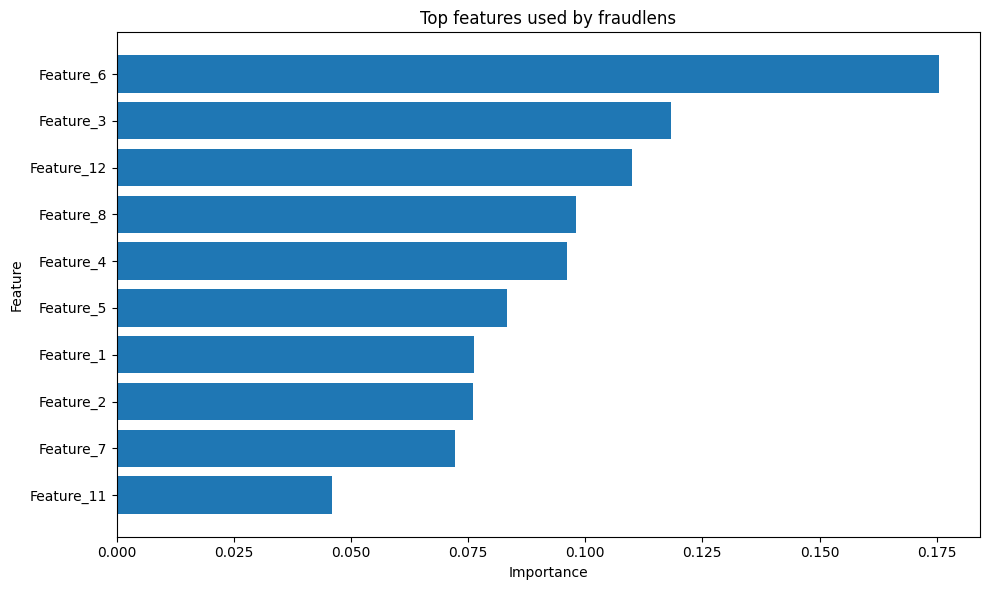

In [43]:
top_features = feature_importance_df.head(10)
plt.figure(figsize = (10,6))
plt.barh(
    top_features["Feature"],
    top_features["importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top features used by fraudlens")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [44]:
feature_importance_df.to_csv(
    "../data/feature_importance.csv",
    index=False
)
print("Feature importance saved successfully")

Feature importance saved successfully


In [45]:
prediction_results.to_csv(
    "../data/fraud_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [46]:
investigation_df.to_csv(
    "../data/investigation_cases.csv",
    index=False
)
print("Investigation cases saved successfully")

Investigation cases saved successfully


In [47]:
investigation_report = investigation_df.sort_values(
    "Fraud_Score",
    ascending = False
).copy()
print("="*70)
print("             FRAUDLENS INVESTIGATION REPORT")
print("="*70)
print(investigation_report.to_string(index=False))

             FRAUDLENS INVESTIGATION REPORT
 TransactionID  Decision_Tree_prediction  Random_Forest_predictions  Fraud_Score Risk_level  Investigation_Priority
       3091756                         0                          1     0.998020       High Immediate Investigation
       3073448                         0                          1     0.997480       High Immediate Investigation
       3073399                         0                          1     0.997480       High Immediate Investigation
       3073559                         0                          1     0.997480       High Immediate Investigation
       3074020                         0                          1     0.997480       High Immediate Investigation
       3086301                         0                          1     0.997317       High Immediate Investigation
       3124494                         0                          1     0.995439       High Immediate Investigation
       3124662              

In [48]:
html_report = investigation_report.to_html(
    index=False,
    border=1
)

with open(
    "../data/fraud_investigation_report.html",
    "w",
    encoding="utf-8"
) as file:
    file.write(
        "<html><head>"
        "<title>FraudLens Investigation Report</title>"
        "</head><body>"
        "<h1>FraudLens - Fraud Investigation Report</h1>"
        + html_report +
        "</body></html>"
    )

print("HTML investigation report created successfully!")

HTML investigation report created successfully!


In [49]:
print("Checking available project variables...")

variables = [
    "prediction_results",
    "investigation_df",
    "top_20",
    "top_20_reset"
]

for var in variables:
    print(f"{var}: {'AVAILABLE' if var in globals() else 'NOT AVAILABLE'}")

Checking available project variables...
prediction_results: AVAILABLE
investigation_df: AVAILABLE
top_20: AVAILABLE
top_20_reset: NOT AVAILABLE


In [50]:
print("Checking investigation table...")

print("Investigation table shape:", investigation_df.shape)

# Basic metrics
total_transactions = len(investigation_df)

predicted_fraud = (
    investigation_df["Random_Forest_predictions"] == 1
).sum()

predicted_legitimate = total_transactions - predicted_fraud

high_risk = (
    investigation_df["Risk_level"] == "High"
).sum()

medium_risk = (
    investigation_df["Risk_level"] == "Medium"
).sum()

low_risk = (
    investigation_df["Risk_level"] == "Low"
).sum()

fraud_percentage = (
    predicted_fraud / total_transactions * 100
)

top_investigation_cases = len(investigation_df)

print("\n" + "=" * 45)
print("FRAUDLENS PROJECT METRICS")
print("=" * 45)

print("Total Transactions:", total_transactions)
print("Predicted Fraud:", predicted_fraud)
print("Predicted Legitimate:", predicted_legitimate)
print("High Risk:", high_risk)
print("Medium Risk:", medium_risk)
print("Low Risk:", low_risk)
print("Fraud Percentage:", round(fraud_percentage, 2), "%")
print("Top Investigation Cases:", top_investigation_cases)

Checking investigation table...
Investigation table shape: (20, 6)

FRAUDLENS PROJECT METRICS
Total Transactions: 20
Predicted Fraud: 20
Predicted Legitimate: 0
High Risk: 20
Medium Risk: 0
Low Risk: 0
Fraud Percentage: 100.0 %
Top Investigation Cases: 20


In [51]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Predicted Fraud",
        "Predicted Legitimate",
        "High Risk",
        "Medium Risk",
        "Low Risk",
        "Fraud Percentage",
        "Top Investigation Cases"
    ],
    "Value": [
        total_transactions,
        predicted_fraud,
        predicted_legitimate,
        high_risk,
        medium_risk,
        low_risk,
        round(fraud_percentage, 2),
        top_investigation_cases
    ]
})

print("FraudLens Final Summary")
print("=" * 40)
print(final_summary.to_string(index=False))

FraudLens Final Summary
                 Metric  Value
     Total Transactions   20.0
        Predicted Fraud   20.0
   Predicted Legitimate    0.0
              High Risk   20.0
            Medium Risk    0.0
               Low Risk    0.0
       Fraud Percentage  100.0
Top Investigation Cases   20.0


In [52]:
investigation_df.to_csv(
    "fraudlens_investigation_results.csv",
    index=False
)

final_summary.to_csv(
    "fraudlens_project_metrics.csv",
    index=False
)

print("Files exported successfully!")
print("1. fraudlens_investigation_results.csv")
print("2. fraudlens_project_metrics.csv")

Files exported successfully!
1. fraudlens_investigation_results.csv
2. fraudlens_project_metrics.csv


In [53]:
print("=" * 50)
print("FRAUDLENS FINAL VALIDATION")
print("=" * 50)

checks = {
    "Investigation table created": "investigation_df" in globals(),
    "Fraud score available": "Fraud_Score" in investigation_df.columns,
    "Risk level available": "Risk_level" in investigation_df.columns,
    "Transaction ID available": "TransactionID" in investigation_df.columns,
    "Random Forest prediction available": "Random_Forest_predictions" in investigation_df.columns,
    "Investigation priority available": "Investigation_Priority" in investigation_df.columns
}

for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

print("=" * 50)

if all(checks.values()):
    print("FRAUDLENS VALIDATION: PASSED")
else:
    print("FRAUDLENS VALIDATION: CHECK FAILED ITEMS")

FRAUDLENS FINAL VALIDATION
Investigation table created: PASS
Fraud score available: PASS
Risk level available: PASS
Transaction ID available: PASS
Random Forest prediction available: PASS
Investigation priority available: PASS
FRAUDLENS VALIDATION: PASSED


In [54]:
print("\n" + "=" * 60)
print("              FRAUDLENS PROJECT")
print("     Explainable AI Fraud Detection System")
print("=" * 60)

print("\nPROJECT STATUS: COMPLETED")

print("\nKey Components:")
print("✓ Data preprocessing")
print("✓ Exploratory data analysis")
print("✓ Fraud detection")
print("✓ Decision Tree model")
print("✓ Random Forest model")
print("✓ Fraud probability scoring")
print("✓ Risk classification")
print("✓ Investigation priority")
print("✓ High-risk transaction identification")
print("✓ Investigation table")
print("✓ Project metrics")
print("✓ Results exported")

print("\nFinal Investigation Cases:", len(investigation_df))
print("High Risk Cases:", high_risk)
print("Fraud Percentage:", round(fraud_percentage, 2), "%")

print("\nFraudLens is ready for portfolio presentation.")
print("=" * 60)


              FRAUDLENS PROJECT
     Explainable AI Fraud Detection System

PROJECT STATUS: COMPLETED

Key Components:
✓ Data preprocessing
✓ Exploratory data analysis
✓ Fraud detection
✓ Decision Tree model
✓ Random Forest model
✓ Fraud probability scoring
✓ Risk classification
✓ Investigation priority
✓ High-risk transaction identification
✓ Investigation table
✓ Project metrics
✓ Results exported

Final Investigation Cases: 20
High Risk Cases: 20
Fraud Percentage: 100.0 %

FraudLens is ready for portfolio presentation.


In [55]:
import os
print("Exported files")
for file in os.listdir("../"):
    print(file)

Exported files
dashboard
data
matlab
models
notebooks
README.md.txt
src


In [56]:
import os

print("Checking FraudLens project folders...")

folders = [
    "../data",
    "../models",
    "../dashboard",
    "../src",
    "../matlab"
]

for folder in folders:
    print(folder, "->", os.path.exists(folder))

print("\nProject structure check completed.")

Checking FraudLens project folders...
../data -> True
../models -> True
../dashboard -> True
../src -> True
../matlab -> True

Project structure check completed.


In [58]:
print("Checking available model variables...\n")

for name in globals():
    if "model" in name.lower() or "tree" in name.lower() or "forest" in name.lower():
        print(name)

Checking available model variables...

x_model
model_dt
model_rf
model_summary


In [60]:
print("Decision Tree model:",type(model_dt))
print("Random Forest model:",type(model_rf))
print("\nX model type:",type(x_model))
if hasattr(x_model,"Shape"):
    print("X model shape:",x_model.shape)
print("\nModels are ready")

Decision Tree model: <class 'sklearn.tree._classes.DecisionTreeClassifier'>
Random Forest model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>

X model type: <class 'pandas.core.frame.DataFrame'>

Models are ready


In [62]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(model_dt, "../models/decision_tree_model.pkl")
joblib.dump(model_rf, "../models/random_forest_model.pkl")

print("Models saved successfully!")
print("Decision Tree → ../models/decision_tree_model.pkl")
print("Random Forest → ../models/random_forest_model.pkl")

Models saved successfully!
Decision Tree → ../models/decision_tree_model.pkl
Random Forest → ../models/random_forest_model.pkl


In [63]:
import os
print("checking saved models....\n")
for file in[
    "../models/decision_tree_model.pkl",
    "../models/random_forest_model.pkl"
]:
    print(file,"->",os.path.exists(file))

checking saved models....

../models/decision_tree_model.pkl -> True
../models/random_forest_model.pkl -> True


In [64]:
print("Checking feature information...")

if hasattr(x_model, "columns"):
    feature_columns = x_model.columns.tolist()
    print("Number of features:", len(feature_columns))
    print("\nFeatures:")
    for i, col in enumerate(feature_columns, 1):
        print(i, ":", col)
else:
    feature_columns = None
    print("x_model does not have column names.")

Checking feature information...
Number of features: 12

Features:
1 : TransactionID
2 : TransactionDT
3 : TransactionAmt
4 : card1
5 : card2
6 : card3
7 : card5
8 : addr1
9 : addr2
10 : Hour
11 : Day
12 : LogAmount


In [65]:
import joblib

if feature_columns is not None:
    joblib.dump(
        feature_columns,
        "../models/feature_columns.pkl"
    )

    print("Feature columns saved successfully!")
else:
    print("Feature columns were not saved because column names are unavailable.")

Feature columns saved successfully!


In [66]:
import os

print("Checking all FraudLens model files...\n")

model_files = [
    "../models/decision_tree_model.pkl",
    "../models/random_forest_model.pkl",
    "../models/feature_columns.pkl"
]

for file in model_files:
    print(file, "->", os.path.exists(file))

print("\nAll model files checked.")

Checking all FraudLens model files...

../models/decision_tree_model.pkl -> True
../models/random_forest_model.pkl -> True
../models/feature_columns.pkl -> True

All model files checked.


In [1]:
import os
print("Current working directory:")
print(os.getcwd())
model_files = [
    "../models/decision_tree_model.pkl",
    "../models/random_forest_model.pkl",
    "../models/feature_columns.pkl"
    ]
for file in model_files:
    print(file,"->",os.path.exists(file))

Current working directory:
C:\Users\KAJJAM ABHINAV\Desktop\Fraud detection\notebooks
../models/decision_tree_model.pkl -> True
../models/random_forest_model.pkl -> True
../models/feature_columns.pkl -> True


In [2]:
import joblib
decision_tree = joblib.load("../models/decision_tree_model.pkl")
random_forest = joblib.load("../models/random_forest_model.pkl")
feature_columns = joblib.load("../models/feature_columns.pkl")
print("Decisison Tree Loaded:",type(decision_tree))
print("Random Forest loaded Loaded:",type(random_forest))
print("No of feature columns loaded:",type(feature_columns))
print("Models Loaded successfully")

Decisison Tree Loaded: <class 'sklearn.tree._classes.DecisionTreeClassifier'>
Random Forest loaded Loaded: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
No of feature columns loaded: <class 'list'>
Models Loaded successfully


In [5]:
print("Number of saved feature columns:",len(feature_columns))
print("\nFirst 10 feature columns:")
print(feature_columns[:10])
print("\nFeature columns loaded successfully!")

Number of saved feature columns: 12

First 10 feature columns:
['TransactionID', 'TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'Hour']

Feature columns loaded successfully!


In [6]:
print("ALL 12 FEATURE COLUMNS:")
for i, col in enumerate(feature_columns,start=1):
    print(i,"->",col)

ALL 12 FEATURE COLUMNS:
1 -> TransactionID
2 -> TransactionDT
3 -> TransactionAmt
4 -> card1
5 -> card2
6 -> card3
7 -> card5
8 -> addr1
9 -> addr2
10 -> Hour
11 -> Day
12 -> LogAmount


In [8]:
import pandas as pd
import joblib

df = pd.read_csv("../data/fraudlens_features.csv")
feature_columns = joblib.load("../models/feature_columns.pkl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Feature columns:", len(feature_columns))

# Create one test transaction
test_transaction = df[feature_columns].iloc[[0]].copy()

print("\nTest transaction created successfully!")
print("Test transaction shape:", test_transaction.shape)

test_transaction

Dataset loaded successfully!
Dataset shape: (590540, 20)
Feature columns: 12

Test transaction created successfully!
Test transaction shape: (1, 12)


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,Hour,Day,LogAmount
0,2987000,86400,68.5,13926,NaN,150.0,142.0,315.0,87.0,0,2,4.241327


In [9]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("../data/fraudlens_features.csv")

# Load models
decision_tree = joblib.load("../models/decision_tree_model.pkl")
random_forest = joblib.load("../models/random_forest_model.pkl")

# Load feature columns
feature_columns = joblib.load("../models/feature_columns.pkl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of features:", len(feature_columns))

# Create one test transaction
test_transaction = df[feature_columns].iloc[[0]].copy()

print("\nTest transaction created successfully!")
print("Shape:", test_transaction.shape)

test_transaction

Dataset loaded successfully!
Dataset shape: (590540, 20)
Number of features: 12

Test transaction created successfully!
Shape: (1, 12)


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,Hour,Day,LogAmount
0,2987000,86400,68.5,13926,NaN,150.0,142.0,315.0,87.0,0,2,4.241327


In [11]:
decision_prediction = decision_tree.predict(test_transaction)[0]
random_prediction = random_forest.predict(test_transaction)[0]
fraud_probability = random_forest.predict_proba(test_transaction)[0][1]
print("Decision Tree Prediction:",decision_prediction)
print("Random Forst Prediction",random_prediction)
print("Fraud probability:",round(fraud_probability*100,2),"%")

Decision Tree Prediction: 0
Random Forst Prediction 0
Fraud probability: 9.85 %


C:\Users\KAJJAM ABHINAV\Desktop\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [12]:
if fraud_probability>=0.75:
    risk_level = "HIGH"
elif fraud_probability>=0.40:
    risk_level = "MEDIUM"
else:
    risk_level = "LOW"
print("Fraud probability:",round(fraud_probability*100,2),"%")
print("Risk Level:",risk_level)
    

Fraud probability: 9.85 %
Risk Level: LOW


In [13]:
investigation_result = test_transaction.copy()
investigation_result["Decision_Tree_Prediction"] = decision_prediction
investigation_result["Random_Forest_Prediction"] = random_prediction
investigation_result["Fraud_Score"] = fraud_probability
investigation_result["Risk_level"] = risk_level
print("FraudLens investigation result:")
investigation_result

FraudLens investigation result:


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,Hour,Day,LogAmount,Decision_Tree_Prediction,Random_Forest_Prediction,Fraud_Score,Risk_level
0,2987000,86400,68.5,13926,NaN,150.0,142.0,315.0,87.0,0,2,4.241327,0,0,0.098529,LOW


In [14]:
output_file = "../data/fraudlens_investigation_results.csv"
investigation_result.to_csv(
    output_file,
    index = False
)
print("Investigatin result saved successfully!")
print("File:",output_file)

Investigatin result saved successfully!
File: ../data/fraudlens_investigation_results.csv


In [15]:
import shap
print("SHAP version:",shap.__version__)

SHAP version: 0.52.0


In [18]:
explainer = shap.TreeExplainer(random_forest)
shap_values = explainer.shap_values(test_transaction)
print("SHAP explanation generated successfully!")

SHAP explanation generated successfully!


In [19]:
try:
    shap_values_plot = shap_values

    if isinstance(shap_values, list):
        shap_values_plot = shap_values[1]

    shap.waterfall_plot(
        shap.Explanation(
            values=shap_values_plot[0],
            base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value,
            data=test_transaction.iloc[0].values,
            feature_names=feature_columns
        ),
        max_display=12
    )

    plt.show()

except Exception as e:
    print("SHAP plot version issue:", e)
    print("SHAP values were generated, but the visualization format needs adjustment.")

SHAP plot version issue: The waterfall plot can currently only plot a single explanation, but a matrix of explanations (shape (12, 2)) was passed! Perhaps try `shap.plots.waterfall(shap_values[0])` or for multi-output models, try `shap.plots.waterfall(shap_values[0, 0])`.
SHAP values were generated, but the visualization format needs adjustment.


In [20]:
sample_transactions = df[feature_columns].head(20).copy()

dt_predictions = decision_tree.predict(sample_transactions)
rf_predictions = random_forest.predict(sample_transactions)
rf_probabilities = random_forest.predict_proba(sample_transactions)[:, 1]

results = sample_transactions.copy()

results["Decision_Tree_Prediction"] = dt_predictions
results["Random_Forest_Prediction"] = rf_predictions
results["Fraud_Score"] = rf_probabilities

# Assign risk levels
results["Risk_Level"] = pd.cut(
    results["Fraud_Score"],
    bins=[-0.01, 0.40, 0.75, 1.0],
    labels=["LOW", "MEDIUM", "HIGH"]
)

print("Multiple transaction testing completed!")
results.head(20)

Multiple transaction testing completed!


C:\Users\KAJJAM ABHINAV\Desktop\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,Hour,Day,LogAmount,Decision_Tree_Prediction,Random_Forest_Prediction,Fraud_Score,Risk_Level
0,2987000,86400,68.500,13926,NaN,150.0,142.0,315.0,87.0,0,2,4.241327,0,0,0.098529,LOW
1,2987001,86401,29.000,2755,404.0,150.0,102.0,325.0,87.0,0,2,3.401197,0,0,0.058435,LOW
2,2987002,86469,59.000,4663,490.0,150.0,166.0,330.0,87.0,0,2,4.094345,0,0,0.125540,LOW
3,2987003,86499,50.000,18132,567.0,150.0,117.0,476.0,87.0,0,2,3.931826,0,0,0.023311,LOW
4,2987004,86506,50.000,4497,514.0,150.0,102.0,420.0,87.0,0,2,3.931826,0,0,0.054621,LOW
5,2987005,86510,49.000,5937,555.0,150.0,226.0,272.0,87.0,0,2,3.912023,0,0,0.105680,LOW
6,2987006,86522,159.000,12308,360.0,150.0,166.0,126.0,87.0,0,2,5.075174,0,0,0.157945,LOW
7,2987007,86529,422.500,12695,490.0,150.0,226.0,325.0,87.0,0,2,6.048554,0,0,0.296885,LOW
8,2987008,86535,15.000,2803,100.0,150.0,226.0,337.0,87.0,0,2,2.772589,0,0,0.069106,LOW
9,2987009,86536,117.000,17399,111.0,150.0,224.0,204.0,87.0,0,2,4.770685,0,0,0.072241,LOW


In [21]:
high_risk_transactions = results.sort_values(
    by = "Fraud_Score",
    ascending = False
).head(10)
print("Top 10 HIGHEST-RISK TRANSACTIONS")
high_risk_transactions

Top 10 HIGHEST-RISK TRANSACTIONS


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,Hour,Day,LogAmount,Decision_Tree_Prediction,Random_Forest_Prediction,Fraud_Score,Risk_Level
7,2987007,86529,422.50,12695,490.0,150.0,226.0,325.0,87.0,0,2,6.048554,0,0,0.296885,LOW
17,2987017,86668,100.00,11492,111.0,150.0,219.0,204.0,87.0,0,2,4.615121,0,0,0.181455,LOW
14,2987014,86596,10.50,11839,490.0,150.0,226.0,226.0,87.0,0,2,2.442347,0,0,0.179253,LOW
12,2987012,86564,50.00,3786,418.0,150.0,226.0,204.0,87.0,0,2,3.931826,0,0,0.176132,LOW
19,2987019,86730,186.00,7005,111.0,150.0,226.0,264.0,87.0,0,2,5.231109,0,0,0.172014,LOW
6,2987006,86522,159.00,12308,360.0,150.0,166.0,126.0,87.0,0,2,5.075174,0,0,0.157945,LOW
15,2987015,86618,57.95,7055,555.0,150.0,226.0,315.0,87.0,0,2,4.076690,0,0,0.152150,LOW
2,2987002,86469,59.00,4663,490.0,150.0,166.0,330.0,87.0,0,2,4.094345,0,0,0.125540,LOW
18,2987018,86725,47.95,4663,490.0,150.0,166.0,184.0,87.0,0,2,3.890799,0,0,0.120704,LOW
13,2987013,86585,40.00,12866,303.0,150.0,226.0,330.0,87.0,0,2,3.713572,0,0,0.115319,LOW


In [22]:
risk_counts = results["Risk_Level"].value_counts()
print("Risk Level Summary:")
print(risk_counts)

Risk Level Summary:
Risk_Level
LOW       20
MEDIUM     0
HIGH       0
Name: count, dtype: int64


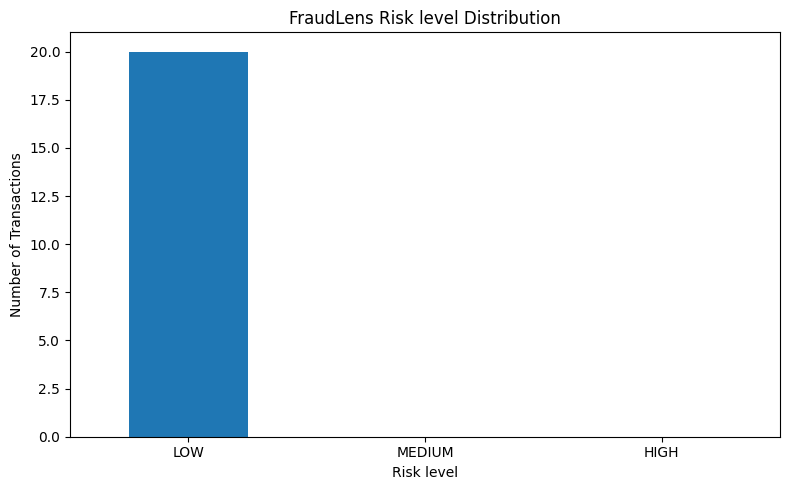

In [23]:
plt.figure(figsize=(8,5))
risk_counts.plot(kind="bar")
plt.title("FraudLens Risk level Distribution")
plt.xlabel("Risk level")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
final_output = "../data/fraudlens_investigation_results.csv"
results.to_csv(
    final_output,
    index = False
)
print("Final investigation results exported successfully!")
print("Saved to:",final_output)
print("Number Of Transactions",len(results))

Final investigation results exported successfully!
Saved to: ../data/fraudlens_investigation_results.csv
Number Of Transactions 20


In [26]:
import os

print("=" * 50)
print("FRAUDLENS FINAL PROJECT CHECK")
print("=" * 50)

files_to_check = [
    "../data/fraudlens_features.csv",
    "../data/fraudlens_investigation_results.csv",
    "../models/decision_tree_model.pkl",
    "../models/random_forest_model.pkl",
    "../models/feature_columns.pkl"
]

for file in files_to_check:
    status = "FOUND" if os.path.exists(file) else "MISSING"
    print(status, "->", file)

print("=" * 50)
print("FraudLens verification completed!")
print("=" * 50)

FRAUDLENS FINAL PROJECT CHECK
FOUND -> ../data/fraudlens_features.csv
FOUND -> ../data/fraudlens_investigation_results.csv
FOUND -> ../models/decision_tree_model.pkl
FOUND -> ../models/random_forest_model.pkl
FOUND -> ../models/feature_columns.pkl
FraudLens verification completed!
